In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Return to the project root if the notebook is opened from the notebooks folder
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

# File paths
prof_data = "data/001MoDe_R1.csv"
personal_data = "data/data.csv"

# Load a dataset and calculate its sampling frequency
def load_dataset(file_path):

    with open(file_path, "r") as file:
        first_line = file.readline().strip()

    data = np.loadtxt(file_path, delimiter=",", skiprows=4)

    # Keep only valid samples
    data = data[data[:, 0] > 0]

    timestamps = data[:, 0]

    # Calculate sampling frequency
    time_differences = np.diff(timestamps)
    time_differences = time_differences[time_differences > 0]

    sampling_frequency = 1000 / np.median(time_differences)

    # Calculate recording duration
    duration = (timestamps[-1] - timestamps[0]) / 1000

    return {
        "data": data,
        "samples": len(data),
        "frequency": sampling_frequency,
        "duration": duration
    }

# Load both datasets
prof = load_dataset(prof_data)
personal = load_dataset(personal_data)

print("Professor dataset")
print("Number of samples:", prof["samples"])
print("Sampling frequency:", round(prof["frequency"], 2), "Hz")
print("Duration:", round(prof["duration"], 2), "seconds")

print("\nPersonal dataset")
print("Number of samples:", personal["samples"])
print("Sampling frequency:", round(personal["frequency"], 2), "Hz")
print("Duration:", round(personal["duration"], 2), "seconds")

Professor dataset
Number of samples: 19588
Sampling frequency: 200.0 Hz
Duration: 180.1 seconds

Personal dataset
Number of samples: 2202
Sampling frequency: 76.92 Hz
Duration: 108.26 seconds


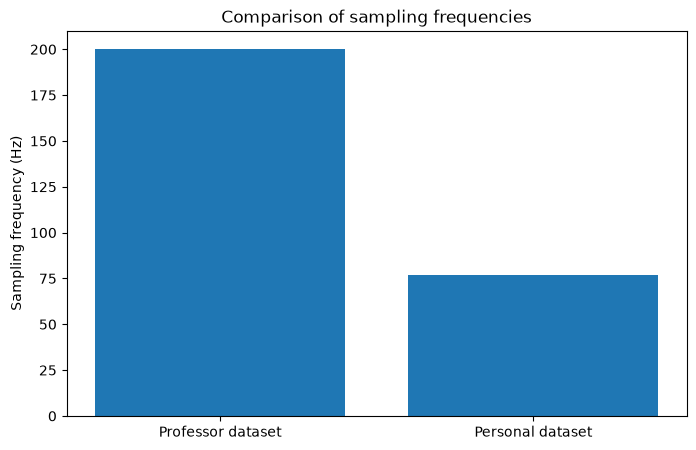

In [3]:
# Compare sampling frequencies

datasets = ["Professor dataset", "Personal dataset"]
frequencies = [prof["frequency"], personal["frequency"]]

plt.figure(figsize=(8, 5))

plt.bar(datasets, frequencies)

plt.ylabel("Sampling frequency (Hz)")
plt.title("Comparison of sampling frequencies")

plt.show()

In [4]:
# Paths to marker files
prof_marker = "data/001MoDe_R1.marker.csv"
personal_marker = "data/marker.csv"

# Display the first lines of each marker file
def inspect_marker_file(file_path):

    print("\nFile:", file_path)

    with open(file_path, "r") as file:
        for i in range(10):
            line = file.readline()
            if not line:
                break
            print(line.strip())

inspect_marker_file(prof_marker)
inspect_marker_file(personal_marker)


File: data/001MoDe_R1.marker.csv
screenWidth 1104;screenHeight 661;cornerX 302;cornerY 80;centerX 552;centerY 330;externalRadius 250;internalRadius 170;borderRadius 1;cursorRadius 16;indexOfDifficulty 28.00696429476858;taskRadius 209.5;taskTolerance 47;borderColor java.awt.Color[r=255,g=255,b=255];backgroundColor java.awt.Color[r=0,g=0,b=0];cursorColorRecord java.awt.Color[r=255,g=0,b=0];cursorColorWait java.awt.Color[r=255,g=255,b=0];autoStart 3600;cycleMaxNumber 6;cycleDuration 20;software LSL-mouse;version 1.2.0rc5;task CircularTarget;isWithLSL false
2021-03-26 17:38:25.650

2021-03-26 17:38:32.325,1616776712325,KeyTyped=32 DoCycleChange
2021-03-26 17:38:32.331,1616776712331,DoCycleChange:DoStartCycleTimedSequence
2021-03-26 17:38:32.333,1616776712333,DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
2021-03-26 17:38:52.336,1616776732336,DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
2021-03-26 17:39:12.340,1616776752340,DoCycleChange:DoRecord RecordDone=1 PauseDone=1 T

In [5]:
import re

def extract_cycles(file_path):

    cycles = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:

            if "DoRecord" in line or "DoPause" in line:

                match = re.search(r"(\d{13}),", line)

                if match:
                    timestamp = int(match.group(1))

                    if "DoRecord" in line:
                        cycles.append({
                            "start": timestamp,
                            "end": None
                        })

                    elif "DoPause" in line and cycles:
                        if cycles[-1]["end"] is None:
                            cycles[-1]["end"] = timestamp

    return cycles


# Extract cycles from both marker files
prof_cycles = extract_cycles(prof_marker)
personal_cycles = extract_cycles(personal_marker)


# Display cycle durations
def display_cycles(cycles, name):

    print("\n", name)

    for i, cycle in enumerate(cycles):

        if cycle["end"] is not None:
            duration = (cycle["end"] - cycle["start"]) / 1000
            print(f"Cycle {i+1}: {duration:.2f} seconds")
        else:
            print(f"Cycle {i+1}: incomplete")


display_cycles(prof_cycles, "PROFESSOR")
display_cycles(personal_cycles, "PERSONAL")


 PROFESSOR
Cycle 1: 20.00 seconds
Cycle 2: 20.01 seconds
Cycle 3: 20.01 seconds
Cycle 4: 20.01 seconds
Cycle 5: 20.01 seconds

 PERSONAL
Cycle 1: 20.00 seconds
Cycle 2: 20.00 seconds
Cycle 3: 20.00 seconds
Cycle 4: 20.00 seconds
Cycle 5: 20.00 seconds


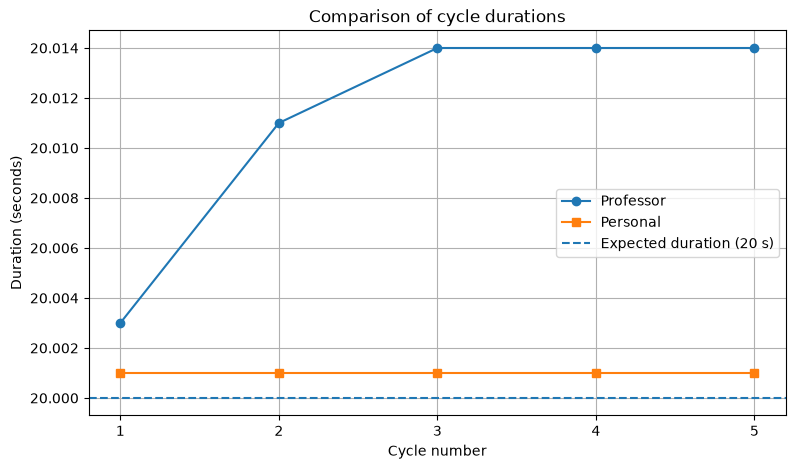

In [6]:
# Calculate cycle durations

def get_durations(cycles):
    return [
        (cycle["end"] - cycle["start"]) / 1000
        for cycle in cycles
        if cycle["end"] is not None
    ]


prof_durations = get_durations(prof_cycles)
personal_durations = get_durations(personal_cycles)

# Create the comparison plot

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(prof_durations) + 1),
    prof_durations,
    marker="o",
    label="Professor"
)

plt.plot(
    range(1, len(personal_durations) + 1),
    personal_durations,
    marker="s",
    label="Personal"
)

plt.axhline(
    y=20,
    linestyle="--",
    label="Expected duration (20 s)"
)

plt.xlabel("Cycle number")
plt.ylabel("Duration (seconds)")
plt.title("Comparison of cycle durations")
plt.xticks(range(1, 6))
plt.legend()
plt.grid()

plt.show()

In [7]:
# Calculate cycle duration statistics

def cycle_statistics(durations):

    print("Mean:", round(np.mean(durations), 4), "seconds")
    print("Standard deviation:", round(np.std(durations), 4), "seconds")
    print("Minimum:", round(np.min(durations), 4), "seconds")
    print("Maximum:", round(np.max(durations), 4), "seconds")


print("PROFESSOR DATA")
cycle_statistics(prof_durations)

print("\nPERSONAL DATA")
cycle_statistics(personal_durations)

PROFESSOR DATA
Mean: 20.0112 seconds
Standard deviation: 0.0043 seconds
Minimum: 20.003 seconds
Maximum: 20.014 seconds

PERSONAL DATA
Mean: 20.001 seconds
Standard deviation: 0.0 seconds
Minimum: 20.001 seconds
Maximum: 20.001 seconds


### Cycle duration analysis

Both recordings show a very high temporal consistency, with cycle durations close to the expected value of 20 seconds.

The professor's dataset has a mean cycle duration of 20.0112 seconds and a standard deviation of 0.0043 seconds. The personal dataset has a mean duration of 20.001 seconds, with no measurable variability at the displayed precision.

These results indicate that both recordings accurately follow the programmed cycle duration. The personal recording shows slightly greater temporal regularity, although the difference is very small and should not be interpreted as a difference in overall recording quality.

### Trajectory analysis

After comparing the temporal characteristics of both recordings, we will now examine the cursor trajectories during the circular task. This analysis will help us assess the shape, regularity and accuracy of the recorded movements.

In [8]:
# Display the first 5 rows of each dataset

print("PROFESSOR DATA")
print(prof["data"][:5])

print("\nPERSONAL DATA")
print(personal["data"][:5])

PROFESSOR DATA
[[1.61677671e+12 5.01000000e+02 5.54000000e+02 1.00000000e+00]
 [1.61677671e+12 4.87000000e+02 5.51000000e+02 1.00000000e+00]
 [1.61677671e+12 4.84000000e+02 5.50000000e+02 1.00000000e+00]
 [1.61677671e+12 4.81000000e+02 5.49000000e+02 1.00000000e+00]
 [1.61677671e+12 4.78000000e+02 5.48000000e+02 1.00000000e+00]]

PERSONAL DATA
[[1.79440144e+12 6.78000000e+02 1.25000000e+02 1.00000000e+00]
 [1.79440144e+12 6.80000000e+02 1.25000000e+02 1.00000000e+00]
 [1.79440144e+12 6.81000000e+02 1.25000000e+02 1.00000000e+00]
 [1.79440144e+12 6.83000000e+02 1.25000000e+02 1.00000000e+00]
 [1.79440144e+12 6.84000000e+02 1.25000000e+02 1.00000000e+00]]


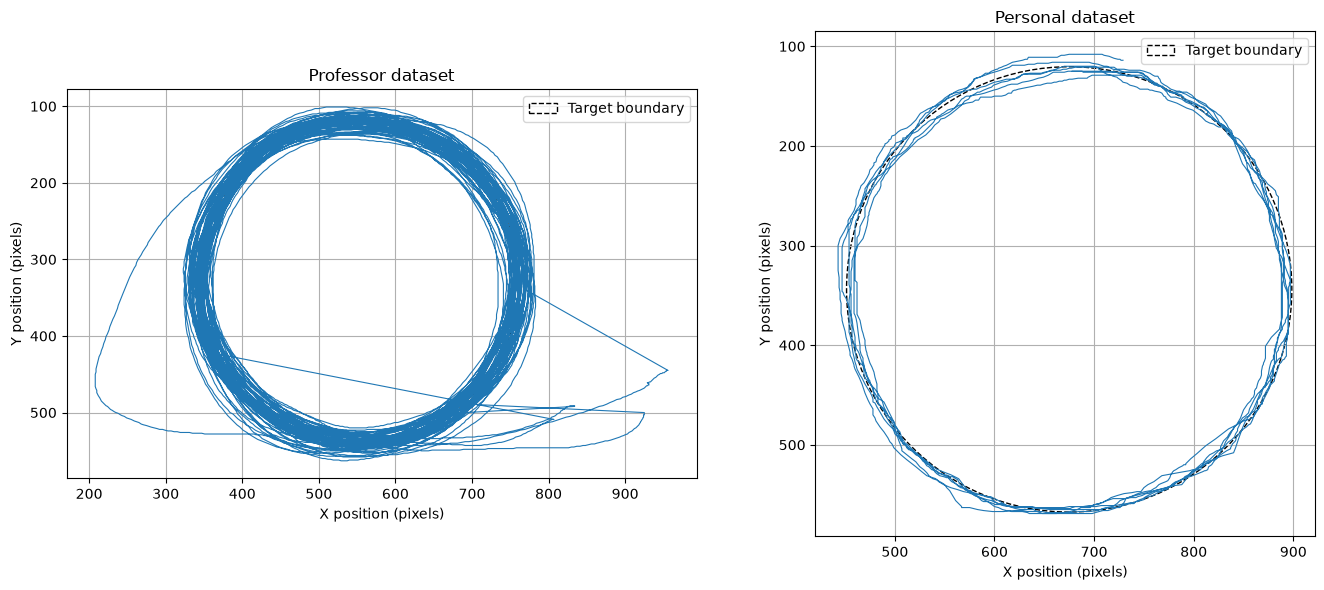

In [9]:
from matplotlib.patches import Circle

# Task parameters
prof_center = (552, 330)
personal_center = (675, 344)

prof_radius = 209.5
personal_radius = 223.5

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Professor trajectory
axes[0].plot(
    prof["data"][:, 1],
    prof["data"][:, 2],
    linewidth=0.8
)

axes[0].add_patch(
    Circle(prof_center, prof_radius, fill=False,
           linestyle="--", label="Target boundary")
)

axes[0].set_title("Professor dataset")
axes[0].set_xlabel("X position (pixels)")
axes[0].set_ylabel("Y position (pixels)")
axes[0].set_aspect("equal")
axes[0].invert_yaxis()
axes[0].legend()
axes[0].grid()

# Personal trajectory
axes[1].plot(
    personal["data"][:, 1],
    personal["data"][:, 2],
    linewidth=0.8
)

axes[1].add_patch(
    Circle(personal_center, personal_radius, fill=False,
           linestyle="--", label="Target boundary")
)

axes[1].set_title("Personal dataset")
axes[1].set_xlabel("X position (pixels)")
axes[1].set_ylabel("Y position (pixels)")
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [10]:
# Calculate radial distance from the task center

def calculate_precision(data, center, radius):

    x = data[:, 1]
    y = data[:, 2]

    distances = np.sqrt(
        (x - center[0])**2 +
        (y - center[1])**2
    )

    radial_error = np.abs(distances - radius)

    return radial_error


prof_error = calculate_precision(
    prof["data"], prof_center, prof_radius
)

personal_error = calculate_precision(
    personal["data"], personal_center, personal_radius
)


# Display precision statistics

print("PROFESSOR DATA")
print("Mean radial error:", round(np.mean(prof_error), 2), "pixels")
print("Standard deviation:", round(np.std(prof_error), 2), "pixels")

print("\nPERSONAL DATA")
print("Mean radial error:", round(np.mean(personal_error), 2), "pixels")
print("Standard deviation:", round(np.std(personal_error), 2), "pixels")

PROFESSOR DATA
Mean radial error: 10.0 pixels
Standard deviation: 18.06 pixels

PERSONAL DATA
Mean radial error: 4.74 pixels
Standard deviation: 3.71 pixels


### Radial accuracy analysis

The personal recording shows a lower mean radial error (4.74 pixels) than the professor's recording (10.00 pixels). Its standard deviation is also considerably lower (3.71 pixels compared to 18.06 pixels).

These results suggest that the personal trajectory remains closer to the theoretical circular path and presents less radial variability. This confirms the visual observations made previously.

However, these results should be interpreted cautiously because the two recordings use different task radii and screen configurations. Radial accuracy alone does not represent the overall quality of circular movement performance.

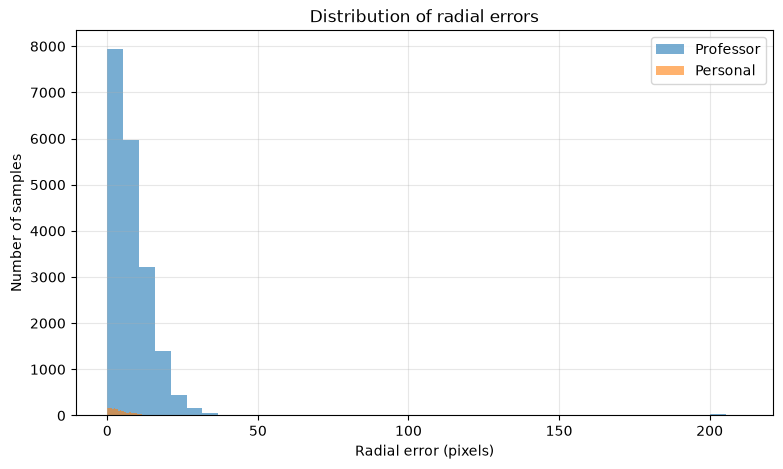

In [11]:
# Compare radial error distributions

plt.figure(figsize=(9, 5))

plt.hist(
    prof_error,
    bins=40,
    alpha=0.6,
    label="Professor"
)

plt.hist(
    personal_error,
    bins=40,
    alpha=0.6,
    label="Personal"
)

plt.xlabel("Radial error (pixels)")
plt.ylabel("Number of samples")
plt.title("Distribution of radial errors")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Distribution of radial errors

The radial error distributions show that most cursor positions are concentrated within the lower error ranges. The number of samples decreases as radial error increases, indicating that large deviations from the theoretical circular path occur less frequently.

This distribution is consistent with the previous results, which showed a lower mean radial error and lower variability in the personal recording.

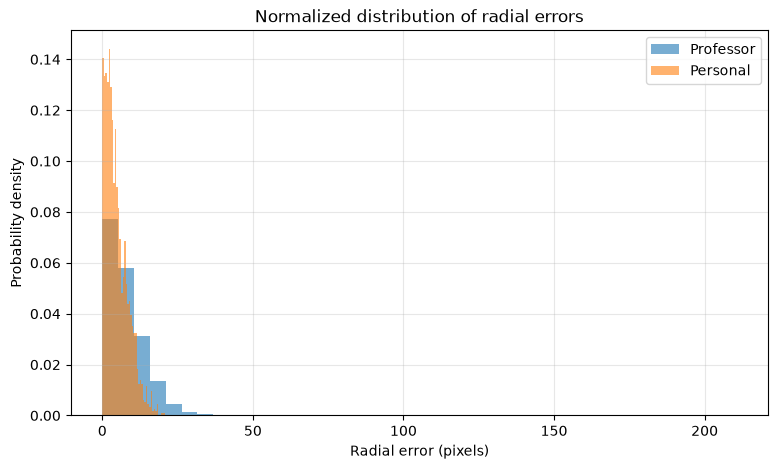

In [12]:
plt.figure(figsize=(9, 5))

plt.hist(
    prof_error,
    bins=40,
    density=True,
    alpha=0.6,
    label="Professor"
)

plt.hist(
    personal_error,
    bins=40,
    density=True,
    alpha=0.6,
    label="Personal"
)

plt.xlabel("Radial error (pixels)")
plt.ylabel("Probability density")
plt.title("Normalized distribution of radial errors")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Comparison of performance indicators

The comparison of performance indicators reveals differences between the two recordings.

The personal dataset shows better radial accuracy, with a lower mean error and lower variability. However, the professor's dataset presents a considerably shorter movement time per lap and a higher performance index (IPe).

This suggests a difference between movement precision and movement speed. The personal recording is more consistent in terms of radial accuracy, whereas the professor's recording achieves a higher information transfer rate.

These results must be interpreted cautiously because the task configurations and acquisition conditions differ between the two datasets.

### Discussion and limitations

The comparison highlights important differences between the two recordings. The personal recording shows lower radial variability and a lower percentage of errors, suggesting more consistent control of the cursor around the target circle. However, the professor's recording presents a much shorter movement time per lap and a higher performance index.

These differences should not be interpreted as a direct comparison of the participants' abilities. Several factors may explain the results, including differences in task configuration, screen dimensions, target radius, sampling frequency and recording conditions.

The number of completed laps also differs considerably between the recordings. This may influence the calculated movement time and performance index. In addition, the marker files indicate five completed recording cycles, although six cycles were initially configured.

Finally, radial accuracy alone does not describe the entire movement performance. Other aspects, such as movement smoothness, speed and trajectory regularity, should also be considered.

Overall, this comparison provides a useful validation of the two datasets and highlights the importance of checking acquisition conditions before interpreting performance indicators.

## Conclusion

This comparison allowed us to analyse and validate two datasets recorded using the MouseReMoCo circular task. Both datasets contain usable cursor trajectories and recording markers, although their acquisition characteristics differ.

The analysis showed differences in sampling frequency, movement duration, radial accuracy and performance indicators. The personal recording presented lower radial variability, while the professor's recording showed a higher movement speed and information transfer rate.

The comparison also highlighted the importance of checking marker files, task parameters and acquisition conditions before interpreting performance results.

Overall, this independent analysis provides an additional validation of the datasets and demonstrates how raw cursor data can be processed to extract meaningful indicators of circular movement performance.